# 01 — Premier regard sur un batch

Objectif : observer le contenu d'**un seul batch** (`batch_1.pt`), sans interprétation.

1. Chargement
2. Champs, formes, types
3. Quelques valeurs
4. Courbes de T_int et U pour 4 simulations tirées au hasard (graine 42)
5. Statistiques de base des cibles et de `solicitation`

## 1. Chargement

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch

from coenergy.data import load_batch

process = psutil.Process()
ram_before = process.memory_info().rss / 1e6

sim = load_batch(1)

ram_after = process.memory_info().rss / 1e6
print(f"RAM du processus : {ram_before:.0f} Mo avant -> {ram_after:.0f} Mo après chargement")

RAM du processus : 290 Mo avant -> 487 Mo après chargement


## 2. Champs, formes, types

In [2]:
rows = []
for f in dataclasses.fields(sim):
    value = getattr(sim, f.name)
    if isinstance(value, torch.Tensor):
        rows.append({"champ": f.name, "type": "Tensor", "forme": tuple(value.shape), "dtype": str(value.dtype)})
    else:
        rows.append({"champ": f.name, "type": type(value).__name__, "forme": len(value), "dtype": "-"})
pd.DataFrame(rows)

,champ,type,forme,dtype
0,HLC,Tensor,"(50000,)",torch.float32
1,CDT,Tensor,"(50000, 3)",torch.float32
2,indoor_temperature,Tensor,"(50000, 480)",torch.float32
3,indoor_U,Tensor,"(50000, 480)",torch.float32
4,solicitation,Tensor,"(50000, 12)",torch.float32
5,solicitation_field_names,list,12,-
6,Hb,Tensor,"(50000, 2)",torch.float32
7,Hb_labels,list,2,-


In [3]:
print("Hb_labels :", sim.Hb_labels)
print("solicitation_field_names :")
for i, name in enumerate(sim.solicitation_field_names):
    print(f"  {i:2d}  {name}")

Hb_labels : ['HLC_mit', 'HLC_ext']
solicitation_field_names :
   0  max_power_wat
   1  start_amplitude_wat
   2  end_amplitude_wat
   3  start_period_hours
   4  end_period_hours
   5  transition_speed
   6  phase_shift
   7  average_fluctuation_wat
   8  prbs_min_duration_hours
   9  prbs_max_duration_hours
  10  prbs_probability_on
  11  prbs_seed


## 3. Quelques valeurs

Cibles : labels des CDT tels que donnés dans l'énoncé (`tau_b`, `tau_n`, `tau_inf`), labels de Hb lus dans le fichier.

In [4]:
cdt_labels = ["tau_b", "tau_n", "tau_inf"]
target_labels = ["HLC"] + list(sim.Hb_labels) + cdt_labels
targets = torch.cat([sim.HLC.unsqueeze(1), sim.Hb, sim.CDT], dim=1)

df_targets = pd.DataFrame(targets.numpy(), columns=target_labels)
df_targets.head()

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
0,219.510010,104.091118,115.418900,59.671638,11.934593,37.149956
1,237.512177,131.026215,106.485962,47.383369,10.639259,27.019434
2,236.414368,109.312347,127.102028,50.282707,10.140277,28.652033
3,263.146393,162.178024,100.968369,45.584885,10.960997,29.496412
4,285.265808,144.631058,140.634750,45.406090,9.762516,28.591862


In [5]:
df_solicitation = pd.DataFrame(sim.solicitation.numpy(), columns=sim.solicitation_field_names)
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(df_solicitation.head())

,max_power_wat,start_amplitude_wat,end_amplitude_wat,start_period_hours,end_period_hours,transition_speed,phase_shift,average_fluctuation_wat,prbs_min_duration_hours,prbs_max_duration_hours,prbs_probability_on,prbs_seed
0,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.313473,2.626946,0.552725,42.0
1,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.915757,3.831513,0.347983,42.0
2,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.912195,1.824391,0.526459,42.0
3,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.000975,0.001950,0.350240,42.0
4,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.124233,0.248466,0.584900,42.0


In [6]:
with pd.option_context("display.max_columns", None, "display.width", 200):
    print("indoor_temperature, 5 premières simulations, 10 premiers pas :")
    display(pd.DataFrame(sim.indoor_temperature[:5, :10].numpy()))
    print("indoor_U, 5 premières simulations, 10 premiers pas :")
    display(pd.DataFrame(sim.indoor_U[:5, :10].numpy()))

indoor_temperature, 5 premières simulations, 10 premiers pas :


,0,1,2,3,4,5,6,7,8,9
0,24.624001,24.630432,24.637468,24.644415,24.651371,24.658400,24.665535,24.672794,24.680187,24.687708
1,24.624001,24.606539,24.595175,24.587292,24.581673,24.577726,24.575121,24.573645,24.573147,24.573509
2,24.624001,24.631075,24.638603,24.646345,24.654202,24.662109,24.670031,24.677937,24.685808,24.693632
3,24.624001,24.641682,24.661562,25.126863,25.112156,25.100931,25.092527,25.086437,25.082256,25.524544
4,24.624001,24.636351,24.649687,24.662811,24.675594,24.688004,24.700045,24.711737,24.723103,24.734165


indoor_U, 5 premières simulations, 10 premiers pas :


,0,1,2,3,4,5,6,7,8,9
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,7000.0,0.0,0.0,0.0,0.0,0.0,7000.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Courbes de T_int et U

4 simulations tirées au hasard (graine 42). L'axe horizontal est l'**indice du pas** : le pas de temps n'est pas encore connu.

Indices tirés : [ 4462 21943 32727 38696]


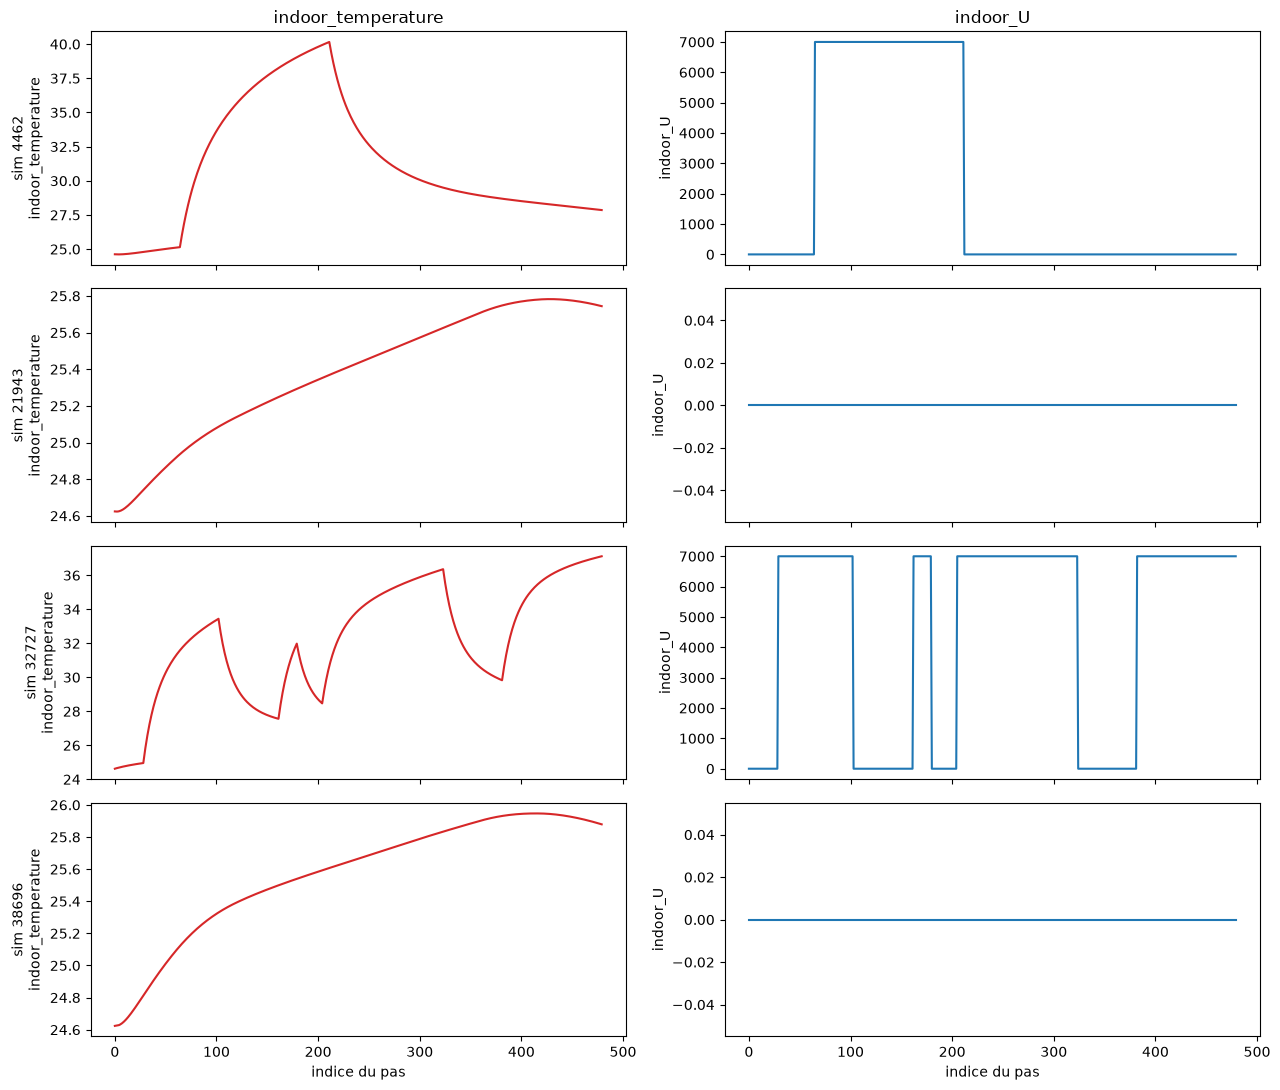

In [7]:
rng = np.random.default_rng(42)
idx = np.sort(rng.choice(sim.indoor_temperature.shape[0], size=4, replace=False))
print("Indices tirés :", idx)

fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True)
for row, i in enumerate(idx):
    axes[row, 0].plot(sim.indoor_temperature[i].numpy(), color="tab:red")
    axes[row, 0].set_ylabel(f"sim {i}\nindoor_temperature")
    axes[row, 1].plot(sim.indoor_U[i].numpy(), color="tab:blue")
    axes[row, 1].set_ylabel("indoor_U")
axes[0, 0].set_title("indoor_temperature")
axes[0, 1].set_title("indoor_U")
axes[-1, 0].set_xlabel("indice du pas")
axes[-1, 1].set_xlabel("indice du pas")
fig.tight_layout()
plt.show()

In [8]:
with pd.option_context("display.max_columns", None, "display.width", 200):
    print("Cibles des 4 simulations tracées :")
    display(df_targets.iloc[idx])
    print("solicitation des 4 simulations tracées :")
    display(df_solicitation.iloc[idx])

Cibles des 4 simulations tracées :


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
4462,183.182877,104.294884,78.888000,58.809246,9.390380,32.364738
21943,214.729202,109.103561,105.625648,47.588287,12.587165,30.820837
32727,225.152695,114.811317,110.341377,63.102665,12.207044,42.855431
38696,269.877014,160.813538,109.063484,34.807854,9.959914,21.797091


solicitation des 4 simulations tracées :


,max_power_wat,start_amplitude_wat,end_amplitude_wat,start_period_hours,end_period_hours,transition_speed,phase_shift,average_fluctuation_wat,prbs_min_duration_hours,prbs_max_duration_hours,prbs_probability_on,prbs_seed
4462,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.649086,1.298173,0.481841,42.0
21943,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.887289,3.774577,0.285734,42.0
32727,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.263913,0.527826,0.847702,42.0
38696,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.856785,3.713570,0.380319,42.0


## 5. Statistiques de base (batch_1, 50 000 simulations)

In [9]:
df_targets.describe()

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,233.075485,120.533142,112.542358,49.963459,11.035908,31.209097
std,31.382204,26.336636,17.162663,10.081826,2.008062,7.505147
min,133.586655,49.805515,59.067413,22.488226,5.657115,11.497870
25%,210.675301,100.886002,100.393305,42.727147,9.610045,25.815419
50%,231.924873,118.891376,112.225872,48.776520,10.786679,30.173258
75%,254.291328,138.484398,124.434126,55.897151,12.205759,35.497673
max,351.191833,220.914017,174.859192,112.838661,22.983259,74.842720


In [10]:
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(df_solicitation.describe())

,max_power_wat,start_amplitude_wat,end_amplitude_wat,start_period_hours,end_period_hours,transition_speed,phase_shift,average_fluctuation_wat,prbs_min_duration_hours,prbs_max_duration_hours,prbs_probability_on,prbs_seed
count,50000.0,50000.0,50000.0,50000.0,50000.0,50000.0,50000.0,50000.0,50000.000000,50000.000000,50000.000000,50000.0
mean,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.998909,1.997818,0.550218,42.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.575905,1.151810,0.202425,0.0
min,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.000025,0.000050,0.200001,42.0
25%,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.500953,1.001906,0.375309,42.0
50%,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,0.999493,1.998987,0.549911,42.0
75%,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.498519,2.997038,0.725581,42.0
max,7000.0,0.0,0.0,0.0,0.0,14.0,0.0,0.0,1.999976,3.999952,0.899995,42.0
